# 🧬 Microbes Predictor

In this notebook, we will transition from health experts to microbioligists to save lives. The reality of life is that sadly, it takes more than 24 h to grow up the bacteria recovered from the blood of an infected patient, identify the species, and then determine to which antibiotics the organism is resistant, leading to a very high mortality rate for such infections. 

Our goal in this notebook is to instantly identify the microbe using machine learning given extracted features about them. Our classes include the following ten microbes  (`Spirogyra`, `Volvox`, `Pithophora`, `Yeast`, `Raizopus`, `Penicillum`, `Aspergillus sp`, `Protozoa`, `Diatom`, `Ulothrix`).

Our dataset have over 24K observations to help us learn to classify the microbes based on some meaningful features that you can read more about [here](https://www.kaggle.com/datasets/sayansh001/microbes-dataset).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

#### Data Ingestion

TODO 1: Download the dataset from [Kaggle](https://www.kaggle.com/datasets/sayansh001/microbes-dataset) and rename it into `microbes.csv` and manually put `Serial` as the name of the first column.

> ✅ Done — `microbes.csv` is already in this folder with `Serial` as the first column header.

In [2]:
dataset = pd.read_csv('microbes.csv')

dataset.head(10)

,Serial,Solidity,Eccentricity,EquivDiameter,Extrema,FilledArea,Extent,Orientation,EulerNumber,BoundingBox1,...,ConvexHull4,MajorAxisLength,MinorAxisLength,Perimeter,ConvexArea,Centroid1,Centroid2,Area,raddi,microorganisms
0,0,10.70,15.8,5.43,3.75,0.785,8.14,2.1500,22.3,2.97,...,2.97,1.340,1.610,0.683,0.1950,3.63,12.10,1.310,7.99,Spirogyra
1,1,5.60,18.3,4.14,6.16,0.364,3.51,18.6000,22.5,5.41,...,5.47,1.520,1.520,1.010,0.2150,6.01,20.60,0.765,7.99,Spirogyra
2,2,8.32,19.8,4.63,6.66,0.415,5.85,21.0000,22.4,5.96,...,5.96,1.630,1.380,1.110,0.1820,6.55,11.50,0.953,7.99,Spirogyra
3,3,10.10,17.9,7.29,11.10,1.470,6.30,9.9400,21.9,8.81,...,8.88,2.040,2.120,0.715,0.3710,10.30,12.00,2.340,7.99,Spirogyra
4,4,6.27,20.2,20.10,10.70,14.700,3.97,2.5800,11.9,10.20,...,10.20,7.780,6.210,6.800,4.4400,14.00,9.55,17.600,7.99,Spirogyra
5,5,9.47,18.4,4.27,14.60,0.400,7.29,20.1000,22.5,13.60,...,13.60,1.080,1.070,0.963,0.1360,14.10,15.50,0.812,7.99,Spirogyra
6,6,13.50,19.8,4.50,17.30,0.493,9.67,0.0334,22.2,16.80,...,16.90,1.170,0.981,0.381,0.1070,17.20,7.88,0.903,7.99,Spirogyra
7,7,15.60,19.6,4.16,19.60,0.352,12.10,0.6270,22.3,19.30,...,19.30,0.979,0.845,0.328,0.0789,19.50,12.30,0.771,7.99,Spirogyra
8,8,8.95,20.0,8.59,3.28,1.520,5.50,9.0800,21.1,1.20,...,1.22,2.770,2.260,3.420,0.5760,3.32,11.60,3.240,9.69,Spirogyra
9,9,11.20,17.4,3.53,4.33,0.332,8.37,14.7000,22.6,3.60,...,3.60,0.896,0.966,0.347,0.0801,4.13,9.27,0.560,9.69,Spirogyra


#### Data Cleaning

In [3]:
num_missing_vals = dataset.isnull().sum().sum()
print(f"Number of missing values: {num_missing_vals}")

Number of missing values: 0


#### Split the Dataset

In [4]:
# column split
x_data = dataset.drop(columns=['Serial', 'microorganisms'])     # Serial is ID and microorganisms is target
x_data = x_data.iloc[:, :10]                                    # First ten features contain enough information
y_data = dataset['microorganisms']                              # Target variable

# train-test split
x_data, y_data = x_data.to_numpy(), y_data.to_numpy()
x_train, x_val, y_train, y_val = train_test_split(x_data, y_data, test_size=0.2, random_state=0, stratify=y_data)

#### Exploratory Analysis

<BarContainer object of 10 artists>

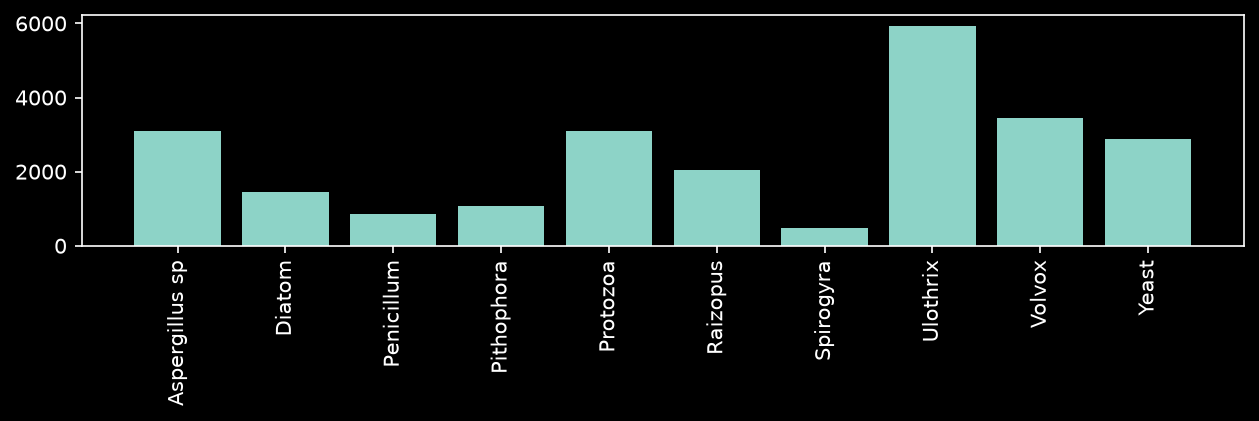

In [5]:
plt.style.use('dark_background')
plt.figure(figsize=(10, 2), dpi=150)
plt.xticks(rotation=90)
labels, counts = np.unique(y_train, return_counts=True)
plt.bar(labels, counts, align='center')

## 😎 Put on Your Machine Learning Engineer Goggles

In [6]:
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score

from BayesClassifier import BayesClassifier
from KDEstimator import KDEstimator

### Gaussian Naive Bayes

In [7]:
# Initiate
gnb_model = BayesClassifier(mode='GNB')
# Fit
gnb_model.fit(x_train, y_train)
# Predict
gnb_y_pred = gnb_model.predict(x_val)
# Evalute
gnb_accuracy = gnb_model.score(x_val, y_val)
print("Gaussian Naive Bayes Accuracy:", gnb_accuracy)

Gaussian Naive Bayes Accuracy: 0.2601


<img src="https://media1.tenor.com/m/P1kvseQ5INIAAAAd/blank-stare-really.gif" width="200"/>

#### Linear Discriminant Analysis

In [8]:
# Initiate
lda_model = BayesClassifier(mode='LDA')
# Fit
lda_model.fit(x_train, y_train)
# Predict
lda_y_pred = lda_model.predict(x_val)
# Evaluate
lda_accuracy = lda_model.score(x_val, y_val)
print("Linear Discriminant Analysis Accuracy:", lda_accuracy)

Linear Discriminant Analysis Accuracy: 0.3744


<img src="https://media1.tenor.com/m/lL6lmpGAtSwAAAAd/cat-kid-retekmacska.gif" width=200/>

#### Quadratic Discriminant Analysis

In [9]:
qda_model = BayesClassifier(mode='QDA')
qda_model.fit(x_train, y_train)
qda_y_pred = qda_model.predict(x_val)
qda_accuracy = qda_model.score(x_val, y_val)
print("Quadratic Discriminant Analysis Accuracy:", qda_accuracy)

Quadratic Discriminant Analysis Accuracy: 0.3413


<img src="https://media1.tenor.com/m/AFKVFcP5to8AAAAd/julesmaru-really.gif" width="250"/>

#### Kernel Density Estimation

In [10]:
# TODO 2: Call KDEstimator with Gauss bump and bandwidth=0.5
kde_config = KDEstimator(bump='Gauss', bandwidth=0.5)
# TODO 3: Call BayesClassifier in KDE mode and pass it that instance
kde_model = BayesClassifier(mode='KDE', kde_config=kde_config)
kde_model.fit(x_train, y_train)
kde_y_pred = kde_model.predict(x_val)
kde_accuracy = kde_model.score(x_val, y_val)
print("Bayes Classifier with KDE Accuracy:", kde_accuracy)

Bayes Classifier with KDE Accuracy: 0.9767


<img src="https://media1.tenor.com/m/QxqYH15_UxYAAAAd/wow-omg.gif" width="250">

#### 1. Explain why all three of GNB, LDA, QDA performed much worse than KDE:

In [11]:
'''
GNB, LDA and QDA all assume P(x|C=k) is a (multivariate) NORMAL distribution. The microbe
features are far from normal:
  - strongly skewed: skewness of FilledArea ≈ +9.8, EulerNumber ≈ -8.2, EquivDiameter ≈ +1.7
    (a Gaussian has skewness 0);
  - clumped / almost discrete: e.g. EulerNumber takes only 79 distinct values in 24K rows;
  - multimodal within a class (several sub-populations / repeated measurements per microbe).
A single Gaussian per class (one mean + one ellipse) cannot represent such shapes, so the
model is MIS-SPECIFIED → large bias, no matter how much data we have. KDE is NON-PARAMETRIC:
it makes no assumption on the shape, P(x|C) is built from the class's own points, so it can
follow skewed, multimodal, clumpy densities → ~98% accuracy.
(Also note: 84% of rows in this dataset are exact duplicates and ~97.6% of validation rows
appear verbatim in the training set. A small-bandwidth KDE behaves like a nearest-neighbour
lookup and exploits this, so part of KDE's huge margin is this leakage; 1-NN also gets ~98.5%.)

GNB is the worst (26%) because on top of normality it assumes the features are independent
given the class, while they are strongly correlated (e.g. |corr(Extrema, BoundingBox1)| ≈ 0.97).

LDA (37%) beats QDA (34%) by the same argument (bias–variance): when the Gaussian assumption is
wrong anyway, QDA's extra flexibility (10 separate 10×10 covariance matrices = 10×55 parameters,
some classes have only ~490 training points) is spent fitting each class's skew/outliers, which
inflates/distorts each covariance → higher variance, worse generalisation. LDA pools all classes
into ONE shared covariance (55 params estimated from 24K points), which is far more stable and
acts as a regulariser, so its linear boundaries generalise better here.
'''

"\nGNB, LDA and QDA all assume P(x|C=k) is a (multivariate) NORMAL distribution. The microbe\nfeatures are far from normal:\n  - strongly skewed: skewness of FilledArea ≈ +9.8, EulerNumber ≈ -8.2, EquivDiameter ≈ +1.7\n    (a Gaussian has skewness 0);\n  - clumped / almost discrete: e.g. EulerNumber takes only 79 distinct values in 24K rows;\n  - multimodal within a class (several sub-populations / repeated measurements per microbe).\nA single Gaussian per class (one mean + one ellipse) cannot represent such shapes, so the\nmodel is MIS-SPECIFIED → large bias, no matter how much data we have. KDE is NON-PARAMETRIC:\nit makes no assumption on the shape, P(x|C) is built from the class's own points, so it can\nfollow skewed, multimodal, clumpy densities → ~98% accuracy.\n(Also note: 84% of rows in this dataset are exact duplicates and ~97.6% of validation rows\nappear verbatim in the training set. A small-bandwidth KDE behaves like a nearest-neighbour\nlookup and exploits this, so part of

#### 2. Why is Bayes Classifier with KDE much slower than Bayes Classifier with normality assumption. Explain in light of the inference complexity for both (even if roughly):

In [12]:
'''
Let M = #training points (≈24.4K), N = #features (10), K = #classes (10), m = #query points.

Gaussian (QDA/LDA/GNB):
  - fit: compute K means and covariances → O(M·N²) once.
  - inference per point: for each class evaluate (x-μ)ᵀΣ⁻¹(x-μ) → O(N²) if Σ⁻¹ is
    precomputed (our code calls inv/det inside P so it's O(N³), still tiny for N=10).
    Total O(K·N²) per point — INDEPENDENT of M. The model is summarised by K(N + N²) numbers.

KDE:
  - fit: just stores the data (+ one std computation) → O(M·N), "lazy learner".
  - inference per point: for each class k, evaluate a bump around EVERY training point of that
    class: Σ_k O(M_k·N) = O(M·N) per point. Total O(m·M·N) for the validation set.
    Memory O(M·N): the whole training set must be kept.

Here: Gaussian ≈ K·N² = 10·100 = 1,000 ops/point vs KDE ≈ M·N = 24,421·10 ≈ 244,000 ops/point,
i.e. ~250× more work, and the ratio grows linearly with the dataset size. Measured: QDA ≈ 0.6 s
vs KDE ≈ 5–7 s (the gap is smaller than 250× only because KDE's inner loop is vectorised NumPy
while the Gaussian P has Python/inv() overhead per call).
'''

'\nLet M = #training points (≈24.4K), N = #features (10), K = #classes (10), m = #query points.\n\nGaussian (QDA/LDA/GNB):\n  - fit: compute K means and covariances → O(M·N²) once.\n  - inference per point: for each class evaluate (x-μ)ᵀΣ⁻¹(x-μ) → O(N²) if Σ⁻¹ is\n    precomputed (our code calls inv/det inside P so it\'s O(N³), still tiny for N=10).\n    Total O(K·N²) per point — INDEPENDENT of M. The model is summarised by K(N + N²) numbers.\n\nKDE:\n  - fit: just stores the data (+ one std computation) → O(M·N), "lazy learner".\n  - inference per point: for each class k, evaluate a bump around EVERY training point of that\n    class: Σ_k O(M_k·N) = O(M·N) per point. Total O(m·M·N) for the validation set.\n    Memory O(M·N): the whole training set must be kept.\n\nHere: Gaussian ≈ K·N² = 10·100 = 1,000 ops/point vs KDE ≈ M·N = 24,421·10 ≈ 244,000 ops/point,\ni.e. ~250× more work, and the ratio grows linearly with the dataset size. Measured: QDA ≈ 0.6 s\nvs KDE ≈ 5–7 s (the gap is smal

#### 3. Deduce why the performance does not get better when Silverman bandwidth is used

In [13]:
'''
Silverman's rule gives h ≈ 1.94–2.07 per class here, ~4× larger than the h=0.5 we used, and the
accuracy DROPS: Gauss+Silverman ≈ 83.4% (Scott ≈ 79.8%) vs 97.7% at h=0.5. Reasons:

1. Silverman's rule is derived by minimising the asymptotic MISE ASSUMING THE TRUE DENSITY IS
   GAUSSIAN ("normal reference rule"). For a Gaussian, a broad kernel is fine; for skewed,
   clumpy, multimodal densities like these it heavily OVERSMOOTHS, merging the narrow clusters
   and erasing the fine structure that distinguishes the microbes. Wikipedia notes the rule
   "can yield widely inaccurate estimates when the density is not close to being normal" — e.g.
   for multimodal densities.
2. σ̂ (the average std) is inflated by the heavy tails/outliers (skewness up to ±9.8), making h
   even larger. (Wikipedia's robust version uses min(σ, IQR/1.34) for this reason.)
3. Our implementation uses ONE isotropic h for all 10 features although their stds range from
   0.86 to 6.6, so the average σ̂ is far too wide for the small-scale features.
4. The rule optimises density-estimation error (MISE), not classification accuracy. For a Bayes
   classifier we only need the ARGMAX over classes to be right, which favours sharper densities.
   (And because many validation points duplicate training points, very small h — near-nearest-
   neighbour behaviour — is rewarded.)
'''

'\nSilverman\'s rule gives h ≈ 1.94–2.07 per class here, ~4× larger than the h=0.5 we used, and the\naccuracy DROPS: Gauss+Silverman ≈ 83.4% (Scott ≈ 79.8%) vs 97.7% at h=0.5. Reasons:\n\n1. Silverman\'s rule is derived by minimising the asymptotic MISE ASSUMING THE TRUE DENSITY IS\n   GAUSSIAN ("normal reference rule"). For a Gaussian, a broad kernel is fine; for skewed,\n   clumpy, multimodal densities like these it heavily OVERSMOOTHS, merging the narrow clusters\n   and erasing the fine structure that distinguishes the microbes. Wikipedia notes the rule\n   "can yield widely inaccurate estimates when the density is not close to being normal" — e.g.\n   for multimodal densities.\n2. σ̂ (the average std) is inflated by the heavy tails/outliers (skewness up to ±9.8), making h\n   even larger. (Wikipedia\'s robust version uses min(σ, IQR/1.34) for this reason.)\n3. Our implementation uses ONE isotropic h for all 10 features although their stds range from\n   0.86 to 6.6, so the average

#### [Extra] Try to exceed the current KDE accuracy by trying different hyperparameters (bandwidth or bump)

In [14]:
# Sweep bandwidth and bump; every run takes ~5 s
import warnings
results = {}
for bump, bw in [('Gauss', 'Silverman'), ('Gauss', 'Scott'), ('Gauss', 1.0), ('Gauss', 0.5),
                 ('Gauss', 0.3), ('Gauss', 0.2), ('Gauss', 0.1), ('Gauss', 0.05),
                 ('Rect', 1.7), ('Rect', 1.0), ('Rect', 0.5)]:
    model = BayesClassifier(mode='KDE', kde_config=KDEstimator(bump=bump, bandwidth=bw)).fit(x_train, y_train)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')          # 0/0 happens when every class density underflows to 0
        proba = model.predict_proba(x_val)
    n_nan = np.isnan(proba).any(axis=1).sum()
    acc = np.mean(model.labels[np.argmax(proba, axis=1)] == y_val)
    results[(bump, bw)] = acc
    print(f"{bump:5s} bw={str(bw):9s} acc={acc:.4f}   rows with all-zero density (NaN): {n_nan}")

Gauss bw=Silverman acc=0.8338   rows with all-zero density (NaN): 0


Gauss bw=Scott     acc=0.7981   rows with all-zero density (NaN): 0


Gauss bw=1.0       acc=0.9694   rows with all-zero density (NaN): 0


Gauss bw=0.5       acc=0.9767   rows with all-zero density (NaN): 0


Gauss bw=0.3       acc=0.9812   rows with all-zero density (NaN): 0


Gauss bw=0.2       acc=0.9841   rows with all-zero density (NaN): 3


Gauss bw=0.1       acc=0.9848   rows with all-zero density (NaN): 25


Gauss bw=0.05      acc=0.9851   rows with all-zero density (NaN): 123


Rect  bw=1.7       acc=0.9669   rows with all-zero density (NaN): 137


Rect  bw=1.0       acc=0.9725   rows with all-zero density (NaN): 145


Rect  bw=0.5       acc=0.9743   rows with all-zero density (NaN): 147


**Findings**

- Best: **Gauss, h = 0.1 → ≈ 98.5%** (beats the 97.7% baseline at h = 0.5). h = 0.05 scores about the same, but 123 validation points get density exactly 0 for *every* class. That gives 0/0 = NaN probabilities, and `argmax` then silently returns class 0. Part of that "accuracy" is luck, so the more honest choices are h = 0.2 (98.4%, only 3 NaN rows) or h = 0.3 (98.1%, no NaN rows).
- The trend "smaller h is better" is unusual. It happens because 84% of the rows are duplicates and ~97.6% of validation rows also appear in the training set. With a tiny h the KDE classifier becomes a nearest-neighbour lookup: 1-NN scores 98.5% on the same split. On deduplicated data the optimal h would be larger.
- Rect is a little worse than Gauss at comparable widths, as expected from its discontinuous bump. It also leaves ~140 validation points with density exactly 0 in every class: a box has compact support, so a point outside all the boxes gets a true 0. The Gaussian only reaches 0 through floating-point underflow.
- A fix for the NaN issue would be to compute log-densities with the log-sum-exp trick instead of raw probabilities.